# This Data Is Perfect!

Flag: **`SIGMOID_77`**

The 93.42% comes from the same applicants being in train and test. Grouped by applicant, the shipped model (scaler + 1-NN) gets **76.66%**, which rounds to 77%.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, LeaveOneOut,
                                     LeaveOneGroupOut, cross_val_predict)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

sns.set_theme(style='whitegrid')
df = pd.read_csv('../task_estonia/applications.csv')
F = ['form_fill_seconds', 'doc_scan_quality', 'photo_match_score',
     'email_domain_age_days', 'ip_geo_distance_km', 'address_history_years']
print(df.shape, '| missing:', df.isna().sum().sum(), '| fraud share:', round(df.label.mean(), 3))
df.head()

(1971, 10) | missing: 0 | fraud share: 0.291


,submission_id,date_of_birth,citizenship,form_fill_seconds,doc_scan_quality,photo_match_score,email_domain_age_days,ip_geo_distance_km,address_history_years,label
0,SUB-000000,2003-08-23,US,190.0551,0.7538,0.8927,2046.6992,2122.1408,5.2450,0
1,SUB-000001,1997-08-23,IT,525.6093,0.7486,0.7737,3139.2054,3091.2242,6.7011,0
2,SUB-000002,2003-03-15,NG,814.3288,0.8282,0.7470,1223.8895,2674.2644,11.3314,1
3,SUB-000003,1996-12-20,PL,654.0383,0.7348,0.6731,3216.9040,2276.8622,10.2939,1
4,SUB-000004,1970-05-19,KZ,96.2900,0.8247,0.7590,1658.5501,1158.3864,4.6990,0


## EDA

In [2]:
df[F].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
form_fill_seconds,1971.0,474.32,172.93,-133.63,361.86,471.20,589.32,1056.01
doc_scan_quality,1971.0,0.76,0.09,0.46,0.71,0.76,0.82,1.05
photo_match_score,1971.0,0.81,0.06,0.63,0.77,0.81,0.85,1.00
email_domain_age_days,1971.0,2541.55,922.18,-344.99,1907.64,2577.31,3124.02,5169.87
ip_geo_distance_km,1971.0,1727.68,661.84,-470.56,1290.45,1724.95,2187.13,3725.65
address_history_years,1971.0,6.64,2.33,-0.36,5.16,6.64,8.20,15.65


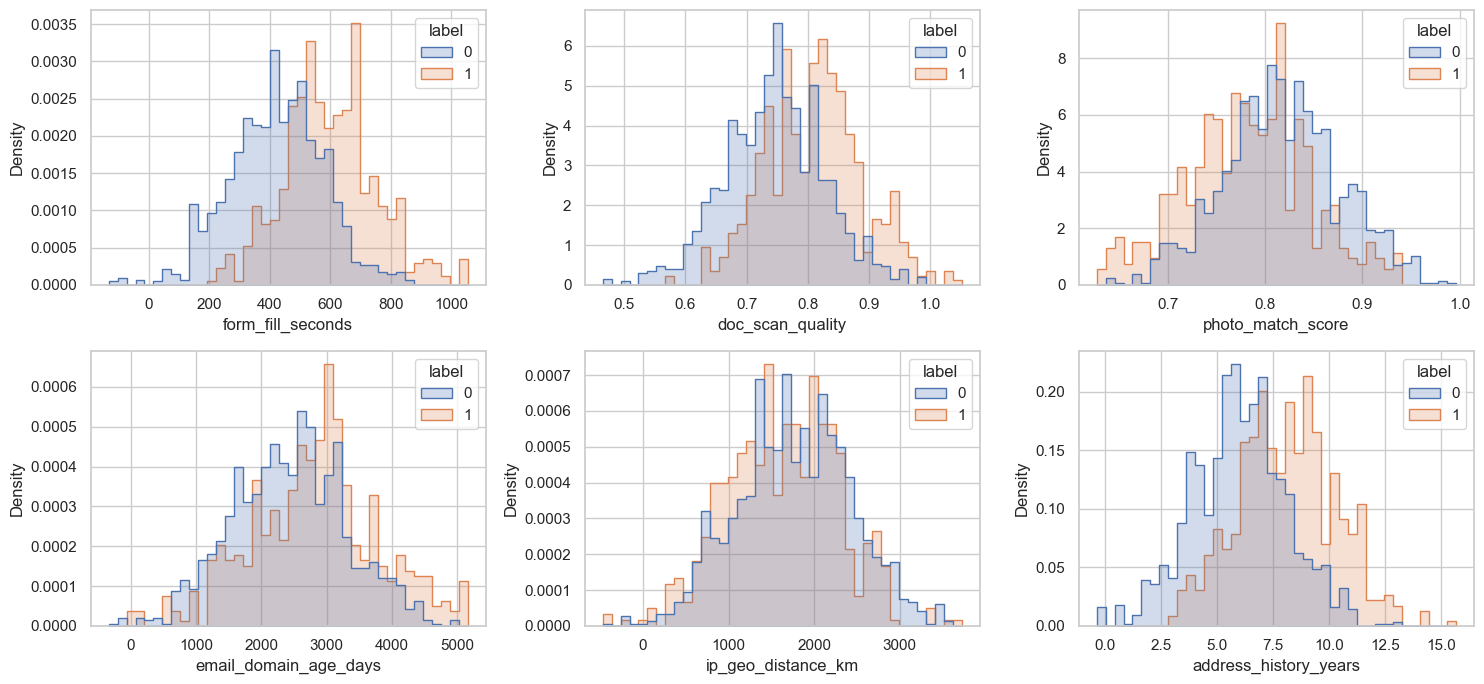

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, F):
    sns.histplot(df, x=c, hue='label', stat='density', common_norm=False, bins=40, ax=ax, element='step')
plt.tight_layout(); plt.show()

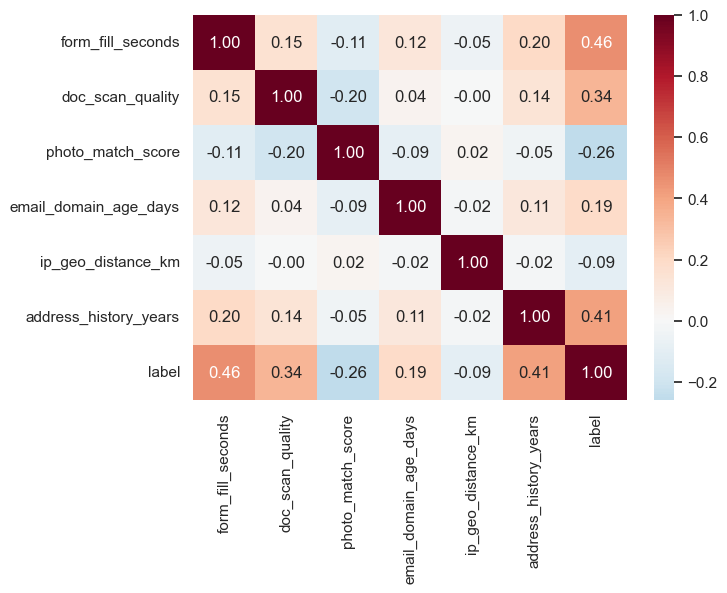

In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[F + ['label']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.show()

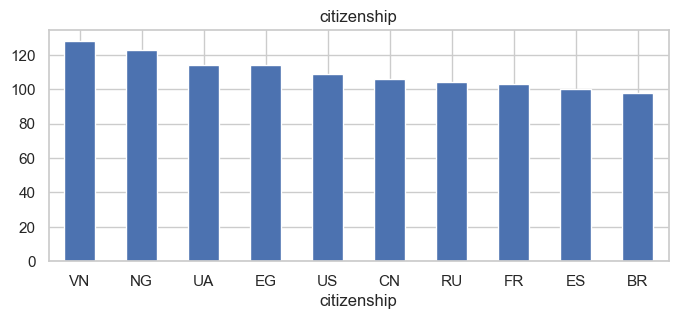

In [5]:
df.citizenship.value_counts().head(10).plot.bar(figsize=(8, 3), title='citizenship', rot=0)
plt.show()

## Reproducing 93.42%

In [6]:
def shipped(seed=1137, scale_first=True, stratify=False, group=False):
    X, y = df[F].values, df.label.values
    if group:
        tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(X, y, applicant))
    else:
        tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=seed,
                                  stratify=y if stratify else None)
    if scale_first:   # as shipped: scaler fit on all rows before the split
        Xs = StandardScaler().fit_transform(X)
        return accuracy_score(y[te], KNeighborsClassifier(1).fit(Xs[tr], y[tr]).predict(Xs[te]))
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(1)).fit(X[tr], y[tr])
    return accuracy_score(y[te], m.predict(X[te]))

applicant = (df.date_of_birth + '|' + df.citizenship).values
print(round(shipped(), 4))

0.9342


## Three suspicious choices

1. `StandardScaler` is fit on all rows before the split (test rows leak into the scaling).
2. One random split, not stratified, one fixed seed.
3. Identity fields are dropped and the split is random: the same person can have several applications.

In [7]:
print('applications:', len(df), '| distinct applicants (dob + citizenship):', len(set(applicant)))
pd.Series(applicant).value_counts().value_counts().sort_index().rename('applicants with n applications')

applications: 1971 | distinct applicants (dob + citizenship): 900


count
1    360
2    195
3    159
4    186
Name: applicants with n applications, dtype: int64

In [8]:
print('labels per applicant (max):', df.groupby(applicant).label.nunique().max())
Xs = StandardScaler().fit_transform(df[F])
nn = NearestNeighbors(n_neighbors=2).fit(Xs).kneighbors(Xs, return_distance=False)[:, 1]
print('nearest neighbour is another application of the same person:', round((applicant[nn] == applicant).mean(), 3))

labels per applicant (max): 1
nearest neighbour is another application of the same person: 0.817


Each person's applications look almost the same and always have the same label. A 1-NN that sees one of them in train finds it again in test.

## Fixing each one alone (20 seeds)

In [9]:
seeds = range(20)
res = {name: [shipped(s, **kw) for s in seeds] for name, kw in {
    'as shipped': {},
    '1. scaler inside the pipeline': dict(scale_first=False),
    '2. stratified split': dict(stratify=True),
    '3. split by applicant': dict(group=True),
}.items()}
res = pd.DataFrame(res)
res.agg(['mean', 'std']).T.round(4)

,mean,std
as shipped,0.9444,0.0124
1. scaler inside the pipeline,0.9435,0.0130
2. stratified split,0.9435,0.0156
3. split by applicant,0.7739,0.0241


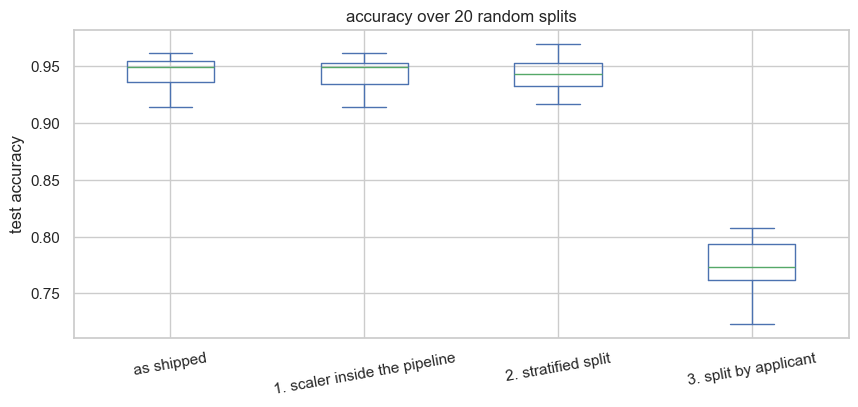

In [10]:
ax = res.plot.box(figsize=(10, 4), rot=10)
ax.set_ylabel('test accuracy'); ax.set_title('accuracy over 20 random splits')
plt.savefig('fixes.png', dpi=120, bbox_inches='tight'); plt.show()

Fixes 1 and 2 stay at ~94%, inside the seed-to-seed spread. Only splitting by applicant moves it, down to ~77%.

## Corrected pipeline and the real number

Same model, scaler inside the pipeline, leave-one-out over **applicants** instead of rows (`LeaveOneGroupOut`, the grouped version of `LeaveOneOut`).

In [11]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
X, y = df[F].values, df.label.values
leaky = accuracy_score(y, cross_val_predict(pipe, X, y, cv=LeaveOneOut()))
true = accuracy_score(y, cross_val_predict(pipe, X, y, cv=LeaveOneGroupOut(), groups=applicant))
print(f'LOO over rows (leaky): {leaky:.4f}')
print(f'LOO over applicants:   {true:.4f}  ->  SIGMOID_{round(true * 100)}')

LOO over rows (leaky): 0.9594
LOO over applicants:   0.7666  ->  SIGMOID_77


Same number if each person is kept once and plain `LeaveOneOut` is run on the 900 applicants:

In [12]:
key = ['date_of_birth', 'citizenship']
variants = {'first application': df.drop_duplicates(key, keep='first'),
            'last application': df.drop_duplicates(key, keep='last'),
            'mean per applicant': df.groupby(key)[F + ['label']].mean()}
for name, d in variants.items():
    yy = d.label.values.astype(int)
    a = accuracy_score(yy, cross_val_predict(pipe, d[F].values, yy, cv=LeaveOneOut()))
    print(f'{name:20s} {len(d)} rows  {a:.4f}  ->  {round(a * 100)}%')

first application    900 rows  0.7656  ->  77%


last application     900 rows  0.7656  ->  77%


mean per applicant   900 rows  0.7667  ->  77%


All versions of the fix land at 76.6-76.7%, i.e. **77%** -> `SIGMOID_77`.